# Отчёт по снижению транзакционной активности клиентов

**Автор:** Юхо Анна Викторовна 
**Дата:** 09.11.2026

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

date_columns = [
    "txn_datetime", "birth_date", "registration_date",
    "card_open_date", "app_last_login",
]

clean = pd.read_csv(
    "clean_data.csv",
    dtype={"txn_id": "string", "client_id": "string", "mcc_code": "string"},
    parse_dates=date_columns,
)
cleaning_log = pd.read_csv("cleaning_log.csv")
campaign = pd.read_csv(
    "campaign_list.csv",
    dtype={"client_id": "string", "group": "string"},
)

clients = clean.drop_duplicates("client_id").copy()
txn = clean.loc[clean["txn_id"].notna()].copy()

## 1. Главное

1. Снижение связано с уменьшением интенсивности использования карты. Среднее число активных клиентов в месяц выросло с 4 716,83 до 5 001,00, но число дней с операциями у активного клиента сократилось с 5,71 до 4,90 дня в месяц, или на 14,2%.

2. Сильнее всего снижение заметно в массовом сегменте. Активность массовых клиентов без приложения уменьшилась на 37,5%, с приложением на 16,3%.

3. Операций стало меньше во всех девяти категориях. Наибольшее снижение зафиксировано в категории «Развлечения и досуг» на 27,2%. Использование токена выросло на 40,7%, но этот рост не компенсировал снижение по остальным каналам.

4. Для кампании отобран 1 971 клиент из четырёх непересекающихся групп. В список вошли 706 массовых клиентов без приложения, 845 массовых клиентов с приложением, 258 премиальных клиентов со снижением операций в категории «Развлечения и досуг» и 162 зарплатных клиента без приложения со снижением операций в категории «Продукты».

## 2. Контекст и задача

Банк заметил снижение числа операций и хочет провести коммуникационную кампанию. Нужно было понять, у каких клиентов активность уменьшилась, с чем связано это снижение и какие группы стоит включить в кампанию. Итоговый список ограничен 2 000 клиентами, каждая группа должна включать не менее 150 человек, а у клиента должно быть согласие на коммуникацию.

## 3. Данные, ограничения и метрика

Исходные файлы содержали 624 400 строк транзакций и 5 730 строк справочника клиентов. После обработки осталось 574 202 успешные операции и 5 660 клиентов. Общая помесячная динамика рассчитана по всем обработанным операциям. Для разрезов использованы 5 527 клиентов, зарегистрированных до 01.01.2024: у каждого из них есть полный период наблюдения. Основная метрика - **среднее число успешных операций на одного клиента в месяц**. Она рассчитывается по всем клиентам сопоставимой группы, включая клиентов с нулём операций. Метрика показывает частоту использования карт банка, но не отражает сумму покупок, прибыль банка и операции клиента в других банках.

In [2]:
comparison_clients = clients.loc[
    clients["registration_date"] < "2024-01-01"
].copy()
comparison_txn = txn.loc[
    txn["client_id"].isin(comparison_clients["client_id"])
].copy()

h1_2024_txn = comparison_txn.loc[
    comparison_txn["txn_datetime"].between("2024-01-01", "2024-07-01", inclusive="left")
].copy()
h1_2025_txn = comparison_txn.loc[
    comparison_txn["txn_datetime"].between("2025-01-01", "2025-07-01", inclusive="left")
].copy()

client_change = comparison_clients.copy()
counts_2024 = h1_2024_txn.groupby("client_id").size()
counts_2025 = h1_2025_txn.groupby("client_id").size()
full_2024_counts = (
    comparison_txn.loc[comparison_txn["txn_datetime"].dt.year == 2024]
    .groupby("client_id").size()
)
stopped_clients = (
    (comparison_clients["client_id"].map(full_2024_counts).fillna(0) > 0)
    & (comparison_clients["client_id"].map(counts_2025).fillna(0) == 0)
).sum()
client_change["h1_2024_monthly_transactions"] = (
    client_change["client_id"].map(counts_2024).fillna(0) / 6
)
client_change["h1_2025_monthly_transactions"] = (
    client_change["client_id"].map(counts_2025).fillna(0) / 6
)

base = h1_2024_txn
current = h1_2025_txn

data_summary = pd.DataFrame({
    "Показатель": [
        "Клиентов после обработки",
        "Успешных операций",
        "Клиентов в сопоставимой группе",
        "Клиентов с операциями в 2024 году и без операций в H1 2025",
    ],
    "Количество": [len(clients), len(txn), len(comparison_clients), stopped_clients],
})
display(data_summary)


,Показатель,Количество
0,Клиентов после обработки,5660
1,Успешных операций,574202
2,Клиентов в сопоставимой группе,5527
3,Клиентов с операциями в 2024 году и без операций в H1 2025,6


## 4. Что выяснили

### 4.1. Операций стало меньше во всех шести сопоставимых месяцах

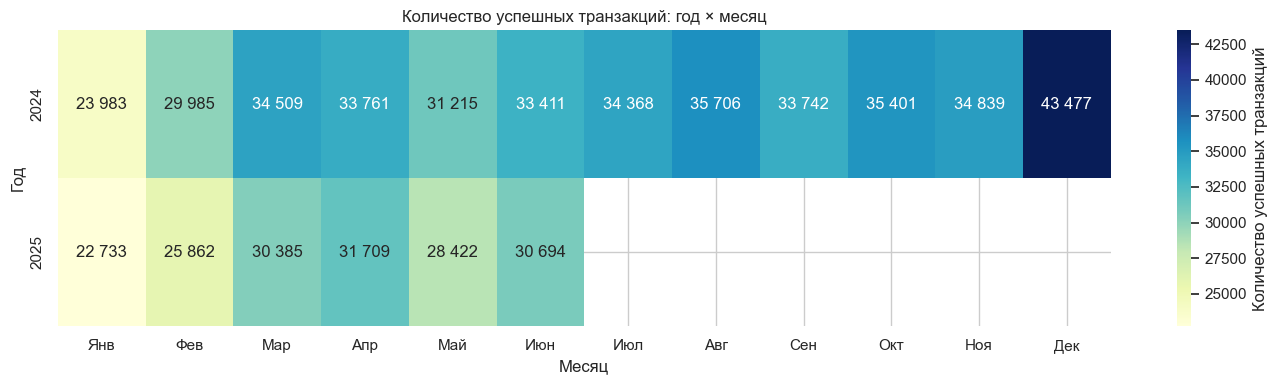

In [3]:
monthly_transaction_counts = (
    txn.assign(year=txn["txn_datetime"].dt.year, month=txn["txn_datetime"].dt.month)
    .groupby(["year", "month"]).size().unstack("month")
    .reindex(columns=range(1, 13))
)
month_labels = ["Янв", "Фев", "Мар", "Апр", "Май", "Июн", "Июл", "Авг", "Сен", "Окт", "Ноя", "Дек"]
monthly_transaction_counts.columns = month_labels
heatmap_labels = monthly_transaction_counts.applymap(
    lambda value: f"{int(value):,}".replace(",", " ") if pd.notna(value) else ""
)

plt.figure(figsize=(14, 4))
sns.heatmap(
    monthly_transaction_counts, annot=heatmap_labels, fmt="", cmap="YlGnBu",
    mask=monthly_transaction_counts.isna(),
    cbar_kws={"label": "Количество успешных транзакций"},
)
plt.title("Количество успешных транзакций: год × месяц")
plt.xlabel("Месяц")
plt.ylabel("Год")
plt.tight_layout()
plt.show()

In [4]:
txn_monthly = txn.assign(
    month=txn["txn_datetime"].dt.to_period("M").dt.to_timestamp(),
    txn_date=txn["txn_datetime"].dt.date,
)
monthly_stats = txn_monthly.groupby("month").agg(
    transactions=("txn_id", "size"),
    active_clients=("client_id", "nunique"),
)
active_client_days = (
    txn_monthly.drop_duplicates(["month", "txn_date", "client_id"])
    .groupby("month").size()
)
monthly_stats["active_client_days"] = active_client_days

months_2024 = monthly_stats.loc["2024-01-01":"2024-06-01"]
months_2025 = monthly_stats.loc["2025-01-01":"2025-06-01"]

period_summary = pd.DataFrame({
    "Январь-июнь 2024": [
        months_2024["transactions"].sum(),
        months_2024["active_clients"].mean(),
        months_2024["active_client_days"].sum() / months_2024["active_clients"].sum(),
        len(h1_2024_txn) / len(comparison_clients) / 6,
    ],
    "Январь-июнь 2025": [
        months_2025["transactions"].sum(),
        months_2025["active_clients"].mean(),
        months_2025["active_client_days"].sum() / months_2025["active_clients"].sum(),
        len(h1_2025_txn) / len(comparison_clients) / 6,
    ],
}, index=[
    "Успешных операций всего",
    "Среднее активных клиентов в месяц",
    "Активных дней на активного клиента в месяц",
    "Операций на сопоставимого клиента в месяц (n=5 527)",
])
period_summary["Изменение, %"] = (
    period_summary["Январь-июнь 2025"]
    / period_summary["Январь-июнь 2024"] - 1
) * 100

display(period_summary.round(2))

,Январь-июнь 2024,Январь-июнь 2025,"Изменение, %"
Успешных операций всего,186864.00,169805.00,-9.13
Среднее активных клиентов в месяц,4716.83,5001.00,6.02
Активных дней на активного клиента в месяц,5.71,4.90,-14.17
Операций на сопоставимого клиента в месяц (n=5 527),5.63,5.08,-9.76


В январе-июне 2025 года число успешных операций снизилось со 186 864 до 169 805, или на 9,1%. При этом активных клиентов в месяц стало больше, но каждый активный клиент пользовался картой в меньшее число дней.

### 4.2. Сильнее всего снизилась активность массового сегмента

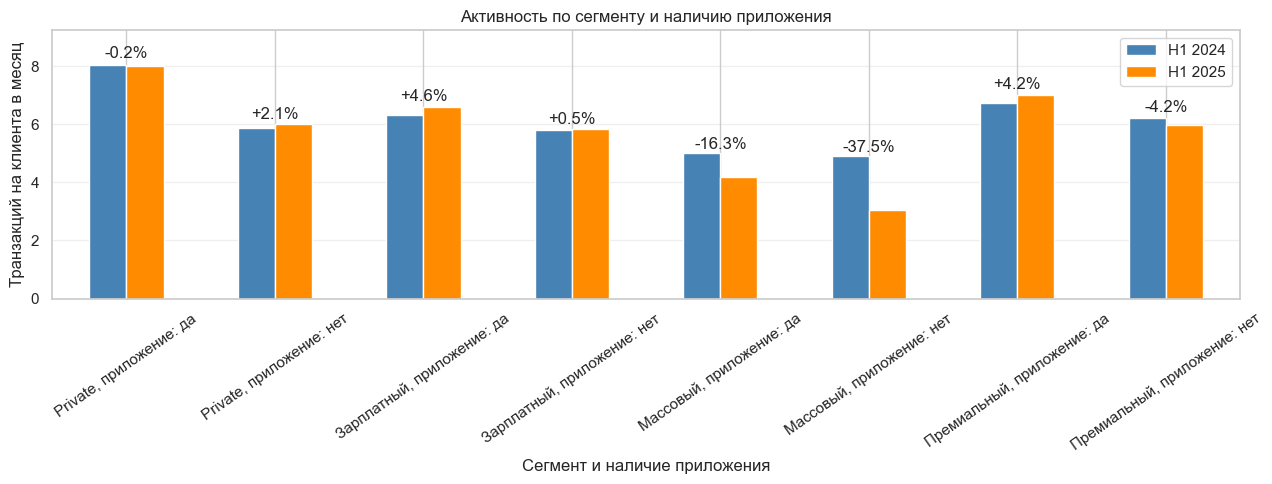

In [5]:
segment_app = client_change.groupby(
    ["segment", "has_mobile_app"]
)[["h1_2024_monthly_transactions", "h1_2025_monthly_transactions"]].mean()

segment_app.index = [
    f"{segment}, приложение: {'да' if app == 'Да' else 'нет'}"
    for segment, app in segment_app.index
]
segment_app.columns = ["H1 2024", "H1 2025"]

ax = segment_app.plot.bar(figsize=(13, 5), color=["steelblue", "darkorange"])
change_pct = (segment_app["H1 2025"] / segment_app["H1 2024"] - 1) * 100
for position, change in enumerate(change_pct):
    height = segment_app.iloc[position].max()
    ax.text(position, height * 1.03, f"{change:+.1f}%", ha="center")

ax.set_title("Активность по сегменту и наличию приложения")
ax.set_xlabel("Сегмент и наличие приложения")
ax.set_ylabel("Транзакций на клиента в месяц")
ax.tick_params(axis="x", rotation=35)
ax.grid(axis="y", alpha=0.3)
ax.margins(y=0.15)
plt.tight_layout()
plt.show()

Среди 5 527 клиентов, наблюдаемых в обоих полугодиях, активность массового сегмента снизилась на 37,5% без приложения и на 16,3% с приложением. В четырёх из шести немассовых подгрупп число операций на клиента в месяц выросло; исключения - premium без приложения (−4,2%) и практически неизменившийся private с приложением (−0,2%).

### 4.3. Снижение затронуло все категории, сильнее всего развлечения и досуг

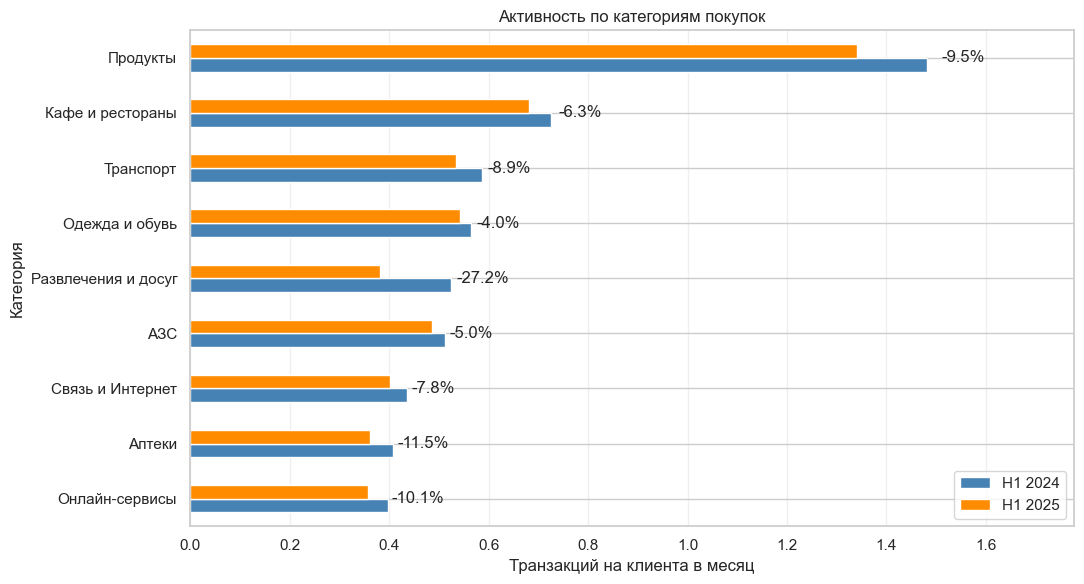

In [6]:
category_activity = pd.DataFrame({
    "H1 2024": h1_2024_txn["category"].value_counts() / len(comparison_clients) / 6,
    "H1 2025": h1_2025_txn["category"].value_counts() / len(comparison_clients) / 6,
}).fillna(0).sort_values("H1 2024")

ax = category_activity.plot.barh(
    figsize=(11, 6), color=["steelblue", "darkorange"]
)
change_pct = (category_activity["H1 2025"] / category_activity["H1 2024"] - 1) * 100
for position, change in enumerate(change_pct):
    width = category_activity.iloc[position].max()
    ax.text(width * 1.02, position, f"{change:+.1f}%", va="center")

ax.set_title("Активность по категориям покупок")
ax.set_xlabel("Транзакций на клиента в месяц")
ax.set_ylabel("Категория")
ax.grid(axis="x", alpha=0.3)
ax.margins(x=0.2)
plt.tight_layout()
plt.show()

У 5 527 сопоставимых клиентов число операций на клиента в месяц снизилось во всех девяти категориях. Самое заметное изменение между первыми полугодиями - в категории «Развлечения и досуг»: −27,2%.

### 4.4. Рост токена компенсировал только часть снижения остальных каналов

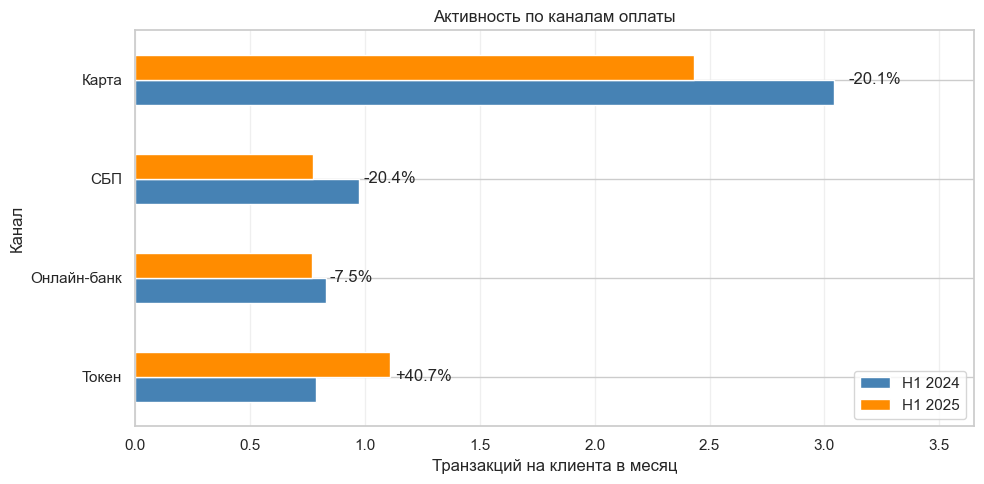

In [7]:
channel_activity = pd.DataFrame({
    "H1 2024": h1_2024_txn["channel"].value_counts() / len(comparison_clients) / 6,
    "H1 2025": h1_2025_txn["channel"].value_counts() / len(comparison_clients) / 6,
}).fillna(0).sort_values("H1 2024")

ax = channel_activity.plot.barh(
    figsize=(10, 5), color=["steelblue", "darkorange"]
)
change_pct = (channel_activity["H1 2025"] / channel_activity["H1 2024"] - 1) * 100
for position, change in enumerate(change_pct):
    width = channel_activity.iloc[position].max()
    ax.text(width * 1.02, position, f"{change:+.1f}%", va="center")

ax.set_title("Активность по каналам оплаты")
ax.set_xlabel("Транзакций на клиента в месяц")
ax.set_ylabel("Канал")
ax.grid(axis="x", alpha=0.3)
ax.margins(x=0.2)
plt.tight_layout()
plt.show()

Между первыми полугодиями токен вырос на 40,7%, а карта, СБП и онлайн-банк снизились на 20,1%, 20,4% и 7,4%. Токен прибавил 1 772,50 операции в месяц и компенсировал 36,8% совокупной потери остальных каналов - 4 812,67 операции в месяц.

### 4.5. Среди клиентов без приложения снижение усиливается с возрастом

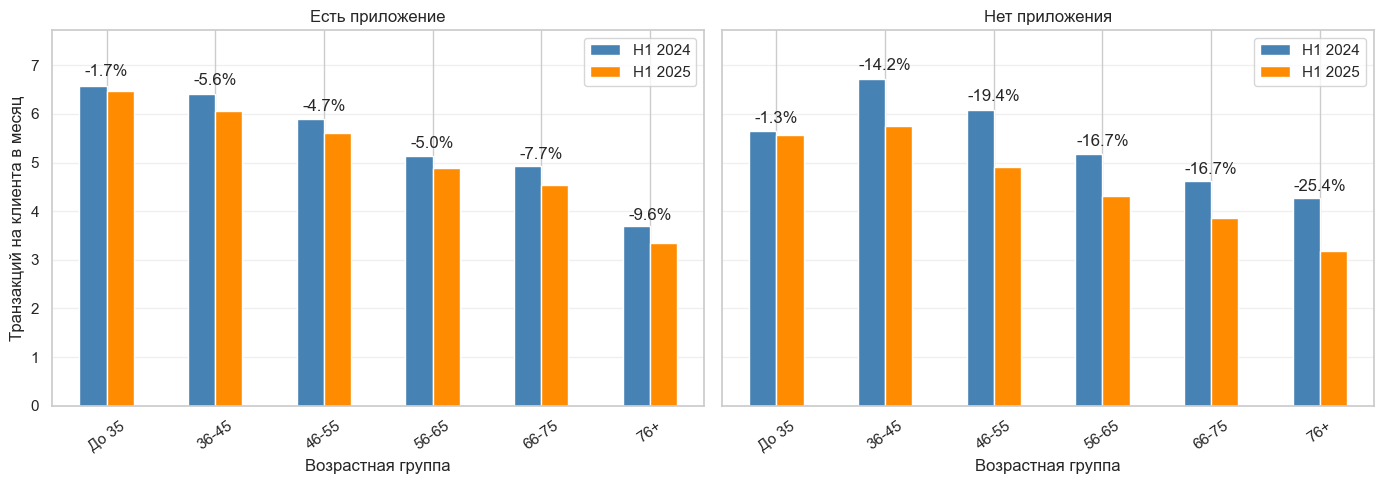

In [8]:
client_change["age_group"] = pd.cut(
    (pd.Timestamp("2025-06-30") - client_change["birth_date"]).dt.days / 365.2425,
    bins=[0, 35, 45, 55, 65, 75, np.inf],
    labels=["До 35", "36-45", "46-55", "56-65", "66-75", "76+"],
)
age_app = client_change.groupby(
    ["age_group", "has_mobile_app"], observed=True
)[["h1_2024_monthly_transactions", "h1_2025_monthly_transactions"]].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, app_value, title in zip(
    axes,
    ["Да", "Нет"],
    ["Есть приложение", "Нет приложения"],
):
    data = age_app.xs(app_value, level="has_mobile_app")
    data.columns = ["H1 2024", "H1 2025"]
    data.plot.bar(ax=ax, color=["steelblue", "darkorange"])
    change_pct = (data["H1 2025"] / data["H1 2024"] - 1) * 100
    for position, change in enumerate(change_pct):
        height = data.iloc[position].max()
        ax.text(position, height * 1.03, f"{change:+.1f}%", ha="center")
    ax.set_title(title)
    ax.set_xlabel("Возрастная группа")
    ax.set_ylabel("Транзакций на клиента в месяц")
    ax.tick_params(axis="x", rotation=35)
    ax.grid(axis="y", alpha=0.3)
    ax.margins(y=0.15)

plt.tight_layout()
plt.show()

Среди 551 клиента 46-55 лет без приложения активность снизилась на 19,4%, а среди 323 клиентов 76 лет и старше - на 25,4%. У клиентов тех же возрастов с приложением снижение составило 4,7% и 9,6%; это связь, а не доказанная причина.

## 5. Группы для кампании

Группы сформированы по признакам клиента и характеру снижения. В итоговый список включены только клиенты с согласием на коммуникацию. Правила не пересекаются: первые две группы относятся к массовому сегменту, третья к премиальному, четвёртая к зарплатному.


In [9]:
h1_2024_per_client = base.groupby("client_id").size() / 6
h1_2025_per_client = current.groupby("client_id").size() / 6

campaign_metrics = campaign.set_index("client_id")
campaign_metrics["H1 2024"] = h1_2024_per_client
campaign_metrics["H1 2025"] = h1_2025_per_client
campaign_metrics = campaign_metrics.fillna(0)

group_summary = campaign_metrics.groupby("group").agg(
    Клиентов=("group", "size"),
    **{
        "H1 2024, операций на клиента в месяц": ("H1 2024", "mean"),
        "H1 2025, операций на клиента в месяц": ("H1 2025", "mean"),
    },
)
group_summary["Изменение между полугодиями, %"] = (
    group_summary["H1 2025, операций на клиента в месяц"]
    / group_summary["H1 2024, операций на клиента в месяц"] - 1
) * 100

rules = {
    "Группа 1": "Массовый сегмент, нет приложения, снизились общая активность и число активных дней",
    "Группа 2": "Массовый сегмент, есть приложение, снизились общая активность и число активных дней",
    "Группа 3": "Премиальный сегмент, снизились общая активность и операции в категории «Развлечения и досуг»",
    "Группа 4": "Зарплатный сегмент, нет приложения, снизились общая активность и операции в категории «Продукты»",
}
group_summary.insert(0, "Правило", group_summary.index.map(rules))

display(group_summary.round(2))


,Правило,Клиентов,"H1 2024, операций на клиента в месяц","H1 2025, операций на клиента в месяц","Изменение между полугодиями, %"
group,,,,,
Группа 1,"Массовый сегмент, нет приложения, снизились общая активность и число активных дней",706,5.44,2.51,-53.75
Группа 2,"Массовый сегмент, есть приложение, снизились общая активность и число активных дней",845,6.02,3.54,-41.11
Группа 3,"Премиальный сегмент, снизились общая активность и операции в категории «Развлечения и досуг»",258,8.21,5.46,-33.48
Группа 4,"Зарплатный сегмент, нет приложения, снизились общая активность и операции в категории «Продукты»",162,7.02,4.05,-42.33


**Итого:** в кампанию включён 1 971 клиент, до лимита осталось 29 мест.

## 6. Кто не включён в кампанию и почему

In [10]:
all_clients = clients.set_index("client_id")
base_all = base.groupby("client_id").size().reindex(all_clients.index, fill_value=0) / 6
current_all = current.groupby("client_id").size().reindex(all_clients.index, fill_value=0) / 6

full_period = all_clients["registration_date"] < "2024-01-01"
declined = current_all < base_all
has_consent = all_clients["marketing_opt_in"].eq("Да")
selected = all_clients.index.isin(campaign["client_id"])

excluded = pd.Series(index=all_clients.index, dtype="string")
excluded.loc[~full_period] = "Нет полного базового периода"
excluded.loc[full_period & ~declined] = "Активность не снизилась"
excluded.loc[full_period & declined & ~has_consent] = "Нет согласия на коммуникацию"
excluded.loc[full_period & declined & has_consent & ~selected] = "Не подходит под правила четырёх групп"

excluded_summary = excluded.value_counts().rename_axis("Причина").reset_index(name="Клиентов")
excluded_summary["Доля от всех 5 660 клиентов, %"] = excluded_summary["Клиентов"] / len(clients) * 100
display(excluded_summary.round(2))


,Причина,Клиентов,"Доля от всех 5 660 клиентов, %"
0,Активность не снизилась,2555,45.14
1,Не подходит под правила четырёх групп,624,11.02
2,Нет согласия на коммуникацию,377,6.66
3,Нет полного базового периода,133,2.35


## 7. Проверенные гипотезы

1. **Клиенты перенесли покупки в другой банк.** Проверить это нельзя: в двух исходных таблицах нет ни одного поля об операциях клиентов в других банках.
2. **Снижение связано только с декабрьским всплеском.** Не подтвердилось: при сравнении первых полугодий средняя активность 5 527 клиентов снизилась с 5,63 до 5,08 операции на клиента в месяц.
3. **Клиенты полностью перестали пользоваться картами банка.** Не подтвердилось: 6 из 5 527 клиентов (0,11%) совершали успешные операции хотя бы раз за 2024 год, но не совершили ни одной в первом полугодии 2025 года.
4. **Клиенты стали реже платить, но объединили покупки в более крупные чеки.** Не подтвердилось: между первыми полугодиями расходы на одного клиента в месяц уменьшились в Группе 1 (n=706) на 4 837,59 руб., в Группе 2 (n=845) на 3 902,06 руб., в Группе 3 (n=258) на 8 501,85 руб., в Группе 4 (n=162) на 6 335,06 руб. Средний и медианный чеки также уменьшились.
5. **Общее снижение объясняется переходом на токен.** Не подтвердилось: между первыми полугодиями токен прибавил 1 772,50 операции в месяц, а карта, СБП и онлайн-банк вместе потеряли 4 812,67; рост токена компенсировал 36,8% этого сокращения.

## 8. Приложение

### Краткий журнал обработки

In [11]:
important_issues = [
    "Полные дубли строк клиентов",
    "Полные дубли транзакций",
    "Разные написания одинаковых категорий",
    "Предполагаемый скрытый пропуск, обозначенный кодом -999",
    "Часть доходов записана в тысячах рублей вместо рублей",
    "Операции находятся вне заявленного периода анализа",
    "Повторяющиеся txn_id с различающимся временем",
    "Для операции нет клиента в справочнике clients",
    "Отклонённые операции и возвраты не отражают состоявшуюся покупательскую активность",
    "Для одного client_id конфликтуют город или сегмент",
]

log_summary = cleaning_log.loc[
    cleaning_log["issue"].isin(important_issues),
    ["field", "issue", "n_rows", "action"],
].rename(columns={
    "field": "Поле",
    "issue": "Что найдено",
    "n_rows": "Строк, n",
    "action": "Что сделано",
})
display(log_summary.reset_index(drop=True))

,Поле,Что найдено,"Строк, n",Что сделано
0,Все поля,Полные дубли строк клиентов,40,Удалены полные дубли
1,Все поля,Полные дубли транзакций,1304,Удалены полные дубли
2,category,Разные написания одинаковых категорий,61301,Названия приведены к единому виду
3,monthly_income,"Предполагаемый скрытый пропуск, обозначенный кодом -999",60,Заменено на стандартный пропуск
4,monthly_income,Часть доходов записана в тысячах рублей вместо рублей,143,Значения умножены на 1000
5,txn_datetime,Операции находятся вне заявленного периода анализа,84,Операции исключены из аналитической таблицы
6,"txn_id, txn_datetime",Повторяющиеся txn_id с различающимся временем,196,Для каждого txn_id оставлена строка с максимальным txn_datetime
7,transactions.client_id,Для операции нет клиента в справочнике clients,28081,Операции исключены из аналитической таблицы
8,status,Отклонённые операции и возвраты не отражают состоявшуюся покупательскую активность,18816,Операции исключены из основной метрики активности
9,"clients.client_id, city, segment",Для одного client_id конфликтуют город или сегмент,30,Клиенты исключены из аналитической выборки


### Методика

#### Как выполнен расчёт

Для сравнения сформирована группа из 5 527 клиентов, зарегистрированных до 01.01.2024. В расчёт включены только успешные операции за январь-июнь 2024 и январь-июнь 2025 года. Для каждого клиента рассчитано среднемесячное число операций; клиенты без операций учтены с нулевым значением. Снижение зафиксировано, если активность клиента в 2025 году оказалась ниже активности в 2024 году.

#### Формулы

**Активность клиента в месяц**

<div style="text-align:center; margin:0.25em 0 0.7em;">
  <span style="display:inline-block;">
    <span style="display:block; border-bottom:1px solid #444; padding:0 0.8em 0.15em;">Число успешных операций клиента за полугодие</span>
    <span style="display:block; padding-top:0.15em;">6</span>
  </span>
</div>

**Средняя активность группы**

<div style="text-align:center; margin:0.25em 0 0.7em;">
  <span style="display:inline-block;">
    <span style="display:block; border-bottom:1px solid #444; padding:0 0.8em 0.15em;">Число успешных операций всех клиентов группы</span>
    <span style="display:block; padding-top:0.15em;">Число клиентов группы × 6</span>
  </span>
</div>

**Изменение активности**

<div style="text-align:center; margin:0.25em 0 0.7em;">
  <span style="display:inline-block; vertical-align:middle;">
    <span style="display:block; border-bottom:1px solid #444; padding:0 0.8em 0.15em;">Активность в 2025 году − активность в 2024 году</span>
    <span style="display:block; padding-top:0.15em;">Активность в 2024 году</span>
  </span>
  <span style="vertical-align:middle;"> × 100%</span>
</div>

**Среднее число дней с операциями в месяц**

<div style="text-align:center; margin:0.25em 0 0.7em;">
  <span style="display:inline-block;">
    <span style="display:block; border-bottom:1px solid #444; padding:0 0.8em 0.15em;">Число уникальных дат с операциями за полугодие</span>
    <span style="display:block; padding-top:0.15em;">6</span>
  </span>
</div>

**Расходы на одного клиента в месяц**

<div style="text-align:center; margin:0.25em 0 0.7em;">
  <span style="display:inline-block;">
    <span style="display:block; border-bottom:1px solid #444; padding:0 0.8em 0.15em;">Сумма успешных операций в RUB</span>
    <span style="display:block; padding-top:0.15em;">Число клиентов группы × 6</span>
  </span>
</div>

В кампанию включены только клиенты с согласием на коммуникацию. Отдельный процентный порог снижения не применялся. В каждой группе должно быть не менее 150 клиентов, общий лимит - 2 000 человек.

### Использование ИИ

ИИ применялся для помощи при написании кода, поиска ошибок, оформления графиков и таблиц и редактирования текста.
